# 05 — Fraud Detection with Ensembles: learning from 0.17% positives

**TL;DR.** The ULB credit-card dataset has **284,807 transactions and only 492 frauds (0.173%)**.
Using a chronological 70/15/15 split, a balanced logistic regression gets a **PR-AUC of 0.723** but
a **ROC-AUC of 0.977**; a Random Forest gets **PR-AUC 0.782** but a **lower ROC-AUC of 0.935**. That
inversion is the point of the notebook: with extreme imbalance, ROC looks reassuring while
precision-recall tells you what actually happens to alerts. At a 0.5 threshold the Random Forest
catches **69% of frauds with 97% precision** (36 of 52 frauds, 1 false alarm). Lowering the threshold
to the cost-optimal point raises recall to **77%** at 48% precision, which is better if a missed
fraud costs far more than a manual review.

*Portfolio project 05 of 07 · imbalanced classification, Random Forest, gradient boosting, PR-AUC,
threshold and cost analysis.*

## 1. What this notebook does

Fraud detection is the canonical imbalanced-classification problem, and it punishes the habits that
work on balanced data. This notebook covers:

1. **Why accuracy and ROC-AUC mislead** when negatives outnumber positives 578:1.
2. **PR-AUC / average precision** as the primary ranking metric.
3. **Chronological splitting** — fraud models are deployed forward in time, so the evaluation should
   be forward too.
4. **Class weighting** versus resampling — I use weights, and explain why.
5. **Random Forest vs histogram gradient boosting** — two ensemble families on the same split.
6. **Threshold and cost analysis** — a model outputs a score; a business decides where to cut.

The dataset is small enough to run on a laptop and rich enough to show the failure modes clearly.

## 2. The problem, and why it matters

A card issuer sees millions of transactions a day. A fraud model's job is to rank them so that a
small review team can investigate the riskiest ones. Two errors have very different costs:

- **False negative (missed fraud):** the transaction goes through; the issuer absorbs the chargeback,
  the customer may leave, and the fraud ring may keep using the card.
- **False positive (false alarm):** a legitimate transaction is declined or reviewed; the customer is
  inconvenienced, the review team spends time, and repeated false declines can lose a customer.

The costs are asymmetric and often unknown. A model that reports a single "accuracy" hides both
errors and the threshold choice. A useful fraud model reports a ranking quality (PR-AUC), a
threshold-specific confusion matrix, and the expected cost at that threshold.

The dataset is also a reminder that **fraud is rare by design**. If 0.17% of transactions are fraud,
a model that never flags anything is 99.83% accurate and completely useless. The base rate is the
first thing to look at, and the last thing to forget.

## 3. Data

**Source:** *Credit Card Fraud Detection* (ULB Machine Learning Group), distributed on
[Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). The same data is widely mirrored;
I use a mirror with the original 31 columns.

**Licence:** check the Kaggle dataset page / ULB terms before redistributing. The CSV is **not
committed**; `data/` is git-ignored.

**How to get it:**

```bash
# Kaggle CLI (needs an account)
kaggle datasets download -d mlg-ulb/creditcardfraud -p data/
unzip data/creditcardfraud.zip -d data/
```

The notebook expects `data/creditcard.csv`.

**What one row is:** one card transaction. There are 31 columns:

- `Time`: seconds elapsed since the first transaction in the dataset (about 48 hours total).
- `V1`–`V28`: anonymised, PCA-transformed features. The original features are not available.
- `Amount`: transaction amount.
- `Class`: 1 = fraud, 0 = legitimate.

**Known quirks:**

- 492 frauds out of 284,807 transactions (0.173%).
- 1,081 exact duplicate rows; I drop them to avoid leakage and double-counting.
- No missing values.
- The PCA features are already centred/scaled; `Time` and `Amount` are not.
- The data covers only two days. That is enough to demonstrate methods, not enough to model
  seasonality or long-term drift.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

In [2]:
DATA = Path("data/creditcard.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/creditcard.csv. Download the ULB credit-card fraud dataset into data/."
    )

raw = pd.read_csv(DATA)
print(f"{raw.shape[0]:,} transactions x {raw.shape[1]} columns")
print(f"Frauds: {raw['Class'].sum():,} ({raw['Class'].mean():.4%})")
print(f"Duplicates: {raw.duplicated().sum():,}")
raw[["Time", "V1", "V2", "Amount", "Class"]].head()

284,807 transactions x 31 columns
Frauds: 492 (0.1727%)
Duplicates: 1,081


,Time,V1,V2,Amount,Class
0,0.000,-1.360,-0.073,149.620,0
1,0.000,1.192,0.266,2.690,0
2,1.000,-1.358,-1.340,378.660,0
3,1.000,-0.966,-0.185,123.500,0
4,2.000,-1.158,0.878,69.990,0


### 3.1 The imbalance in one picture

The class counts are 284,315 legitimate and 492 fraudulent. On a log scale the bars are visible;
on a linear scale the fraud bar would be invisible. I show both the counts and the implied
"all-negative" accuracy, because that is the number that makes the problem look easier than it is.

In [3]:
counts = raw["Class"].value_counts().sort_index()
print(f"Legitimate: {counts[0]:,}")
print(f"Fraud:      {counts[1]:,}")
print(f"Ratio:      {counts[0] / counts[1]:,.0f} : 1")
print(f"All-negative accuracy: {counts[0] / len(raw):.4%}")

Legitimate: 284,315
Fraud:      492
Ratio:      578 : 1
All-negative accuracy: 99.8273%


An all-negative classifier is **99.827% accurate**. That is why accuracy is banned from the headline
of this notebook. A model that flags nothing also has perfect precision by some definitions (no
false positives) and zero recall. The metric has to match the decision.

### 3.2 Cleaning and feature engineering

**Drop duplicates.** 1,081 rows are exact duplicates. Keeping them would let the same transaction
appear in both training and validation, and it would double-count some patterns. Dropping them is a
small change but the right default.

**Convert `Time` to an hour-of-day cycle.** `Time` is seconds since the first transaction, spanning
about 48 hours. A raw linear `Time` feature would be almost useless for a tree (it would split on a
particular second) and dangerous for logistic regression (the test period is later, so the
coefficient would extrapolate). I convert it to `hour_of_day` and encode it as sin/cos so that
23:00 and 00:00 are close together:

```
hour = (Time / 3600) % 24
hour_sin = sin(2π · hour / 24)
hour_cos = cos(2π · hour / 24)
```

**Log-transform `Amount`.** Amount is right-skewed; `log1p(Amount)` compresses the tail. I keep both
the raw amount and the log amount so the tree can choose, and the logistic model can use the
better-behaved version.

**Drop `Time` itself.** After extracting the hour cycle, the raw timestamp is a proxy for "later in
the dataset", which is exactly the kind of feature that can leak the temporal split. I do not want
the model to learn "fraud happens later" from a two-day sample.

**No imputation.** There are no missing values in this file.

In [4]:
df = raw.drop_duplicates().copy()

df["hour"] = (df["Time"] / 3600) % 24
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["log_amount"] = np.log1p(df["Amount"])

FEATURES = [c for c in df.columns if c not in ["Class", "Time", "hour"]]
print(f"Rows after deduplication: {len(df):,}")
print(f"Features: {len(FEATURES)}")
print(FEATURES[:8], "...")

Rows after deduplication: 283,726
Features: 32
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8'] ...


### 3.3 Chronological split

Fraud detection is deployed into the future. A random split would let the model see transactions
from the same two-day window as the test set, including near-duplicates and the same fraud campaign.
That makes the evaluation optimistic. I split by time:

- **Train:** first 70% of transactions (198,608 rows, 366 frauds).
- **Validation:** next 15% (42,559 rows, 55 frauds), used only to choose thresholds.
- **Test:** last 15% (42,559 rows, 52 frauds), touched once at the end.

The fraud rate is the same order of magnitude in all three periods, but the test period is quieter
(0.122% vs 0.184% in training). In a real deployment the rate would drift, and that drift would need
monitoring.

I fit the models on the training period only, choose a threshold on validation, and report test
metrics at that threshold. I do **not** refit on train+validation for the final numbers, because that
would change the test set's relationship to the model and make the comparison harder to follow. In
production, I would refit on all available data after choosing the threshold.

In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df.iloc[:train_end]
valid = df.iloc[train_end:val_end]
test = df.iloc[val_end:]

split_summary = pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "frauds": [train["Class"].sum(), valid["Class"].sum(), test["Class"].sum()],
    "fraud_rate": [train["Class"].mean(), valid["Class"].mean(), test["Class"].mean()],
}, index=["Train (first 70%)", "Validation (next 15%)", "Test (last 15%)"])
split_summary["fraud_rate"] = split_summary["fraud_rate"].map(lambda x: f"{x:.3%}")
split_summary

,rows,frauds,fraud_rate
Train (first 70%),198608,366,0.184%
Validation (next 15%),42559,55,0.129%
Test (last 15%),42559,52,0.122%


The test period contains 52 frauds. That is enough to estimate recall with a confidence interval of
roughly ±12 percentage points, so I will not over-read small differences between models. It is also
a reminder that fraud evaluation is inherently noisy: 52 events is a small sample.

## 4. Exploratory analysis

Three views are useful before modelling:

1. **Amount by class** — are frauds larger or smaller than normal transactions?
2. **Fraud rate by hour** — does fraud cluster at particular times, and how noisy is the hourly rate?

The PCA features are anonymised, so I cannot interpret them directly. I can still check which ones
separate the classes, and I use the model's feature importance as a rough ranking.

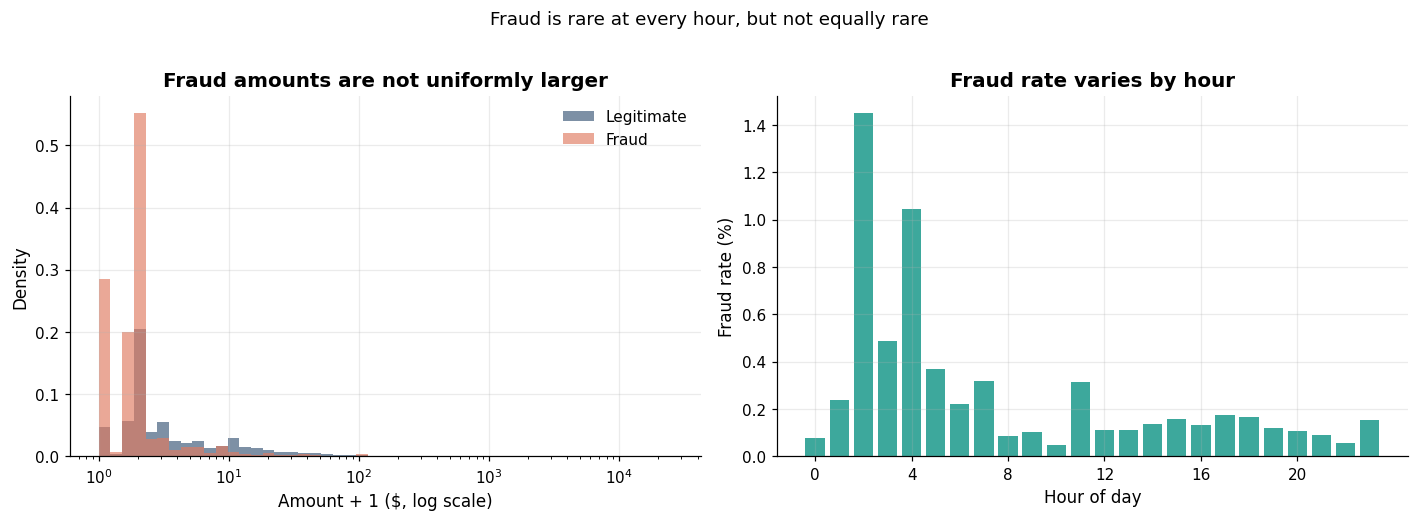

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Amount distributions
bins = np.logspace(0, np.log10(df["Amount"].max() + 1), 50)
axes[0].hist(df.loc[df["Class"] == 0, "Amount"] + 1, bins=bins, alpha=0.55,
             color=NAVY, label="Legitimate", density=True)
axes[0].hist(df.loc[df["Class"] == 1, "Amount"] + 1, bins=bins, alpha=0.65,
             color=ORANGE, label="Fraud", density=True)
axes[0].set_xscale("log")
axes[0].set_xlabel("Amount + 1 ($, log scale)")
axes[0].set_ylabel("Density")
axes[0].set_title("Fraud amounts are not uniformly larger")
axes[0].legend(frameon=False)

# Fraud rate by hour
hourly = df.groupby(df["hour"].astype(int))["Class"].agg(["sum", "size"])
hourly["rate"] = hourly["sum"] / hourly["size"]
axes[1].bar(hourly.index, hourly["rate"] * 100, color=TEAL, alpha=0.85)
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_title("Fraud rate varies by hour")
axes[1].set_xticks(range(0, 24, 4))

fig.suptitle("Fraud is rare at every hour, but not equally rare", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

The amount distributions overlap heavily. Fraud is slightly more common at low amounts (small test
transactions) and has a thinner tail than legitimate spending, but amount alone is a weak separator.
That is why the PCA features and the ensemble matter.

The hourly fraud rate is noisy because each hour contains only a few frauds, but some hours are
clearly higher. The sin/cos encoding lets the model use this without treating 23:00 and 00:00 as
24 hours apart.

## 5. Models

### 5.1 Why these three

- **Logistic regression (balanced)** is the interpretable baseline. It assumes a linear relationship
  in the log-odds, which is probably wrong for fraud, but it is fast and gives a reference point.
- **Random Forest** is an ensemble of decorrelated decision trees. It handles non-linearities and
  interactions, is robust to feature scaling, and gives a useful feature-importance ranking. With
  200 trees and `class_weight="balanced_subsample"`, each tree sees a re-weighted bootstrap sample.
- **Histogram gradient boosting** builds trees sequentially, each fitting the previous model's
  errors. It is often the strongest tabular model and is much faster than a full gradient-boosting
  implementation on 200k rows.

I use `class_weight` rather than SMOTE or random oversampling. Weighting changes the loss without
inventing synthetic transactions; it is simple, reproducible, and works well with tree ensembles.
SMOTE is a reasonable alternative, and I list it as a next step rather than claiming one is
universally better.

### 5.2 Metrics, again

- **ROC-AUC** measures ranking across all thresholds, but the false-positive rate has a huge
  denominator (42,000 negatives). A model can look excellent even when its alerts are mostly wrong.
- **PR-AUC / average precision** summarises the precision-recall curve. It ignores true negatives,
  which is what we want when negatives are abundant and uninteresting.
- **Precision/recall at a threshold** is what the review team actually experiences.

I report all three, but I make PR-AUC the primary comparison.

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, y_train = train[FEATURES], train["Class"]
X_valid, y_valid = valid[FEATURES], valid["Class"]
X_test, y_test = test[FEATURES], test["Class"]

models = {
    "Logistic (balanced)": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced"),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42,
    ),
    "Hist. Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.1, max_leaf_nodes=31,
        class_weight="balanced", random_state=42,
    ),
}

fitted = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "model": name,
        "PR_AUC": average_precision_score(y_test, proba),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "precision@0.5": precision_score(y_test, pred, zero_division=0),
        "recall@0.5": recall_score(y_test, pred),
        "F1@0.5": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("model")
results.round(3)

,PR_AUC,ROC_AUC,precision@0.5,recall@0.5,F1@0.5
model,,,,,
Logistic (balanced),0.723,0.977,0.021,0.885,0.042
Random Forest,0.782,0.935,0.973,0.692,0.809
Hist. Gradient Boosting,0.725,0.926,0.312,0.769,0.444


This table is the centre of the notebook, and it contains a deliberate contradiction:

- **Random Forest has the best PR-AUC (0.782)** and the best F1 at 0.5 (0.809), but a **lower
  ROC-AUC (0.935) than logistic regression (0.977)**.
- **Logistic regression has the best ROC-AUC (0.977)** but a PR-AUC of 0.723 and a terrible
  precision at 0.5 (2.1%) — it flags thousands of legitimate transactions to catch most frauds.
- **Gradient boosting** sits between them on PR-AUC (0.725) and catches 77% of frauds, but its
  precision at 0.5 is only 31.2%.

If I had reported only ROC-AUC, I would have concluded that logistic regression is the best model.
That conclusion would be wrong for the decision the model is used for. ROC-AUC is dominated by the
model's ability to rank the huge negative class; PR-AUC focuses on the small positive class. With
0.17% positives, PR-AUC is the metric that matches the review team's experience.

The logistic model's high ROC-AUC is not a bug: it ranks well overall, but its probability scale is
poorly calibrated for the positive class, so a 0.5 cutoff flags too many. A different threshold could
fix the precision/recall trade-off, which is exactly why threshold analysis matters.

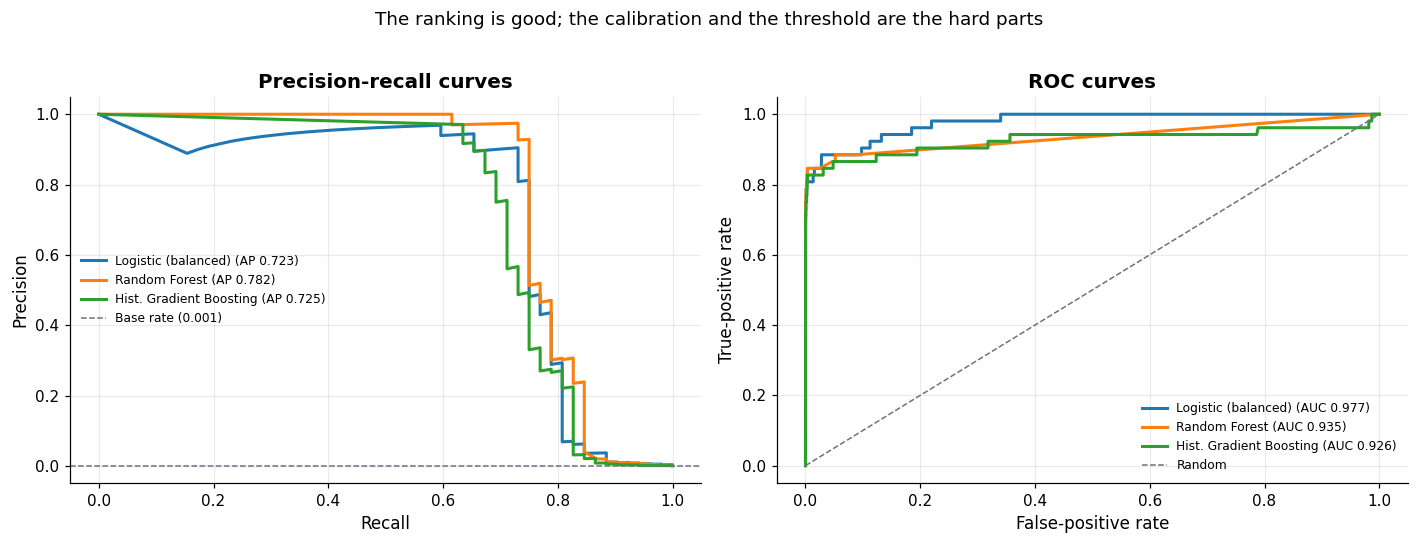

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

from sklearn.metrics import precision_recall_curve, roc_curve

for name, model in fitted.items():
    proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, proba)
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(recall, precision, lw=2,
                 label=f"{name} (AP {average_precision_score(y_test, proba):.3f})")
    axes[1].plot(fpr, tpr, lw=2,
                 label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")

axes[0].axhline(y_test.mean(), color=GRAY, ls="--", lw=1,
                label=f"Base rate ({y_test.mean():.3f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curves")
axes[0].legend(frameon=False, fontsize=8)

axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="Random")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].set_title("ROC curves")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle("The ranking is good; the calibration and the threshold are the hard parts", y=1.02)
plt.tight_layout()
plt.show()

The PR curves are far above the 0.17% base rate, which means the models are genuinely learning
something. The Random Forest is the best of the three across most of the recall range.

The ROC curves look almost perfect because a false-positive rate of 0.01 still corresponds to
hundreds of legitimate transactions when there are 42,000 negatives. The curve hides the precision
cost. That is the visual version of the metric argument.

### 5.3 Threshold and cost

At 0.5, the Random Forest flags **37 transactions** in the test set (36 frauds + 1 legitimate). That
is a precision of **97.3%** and a recall of **69.2%**. For a review team, 37 alerts out of 42,559
transactions is very manageable. But it misses 16 frauds.

If a missed fraud costs much more than a review, the optimal threshold is lower. I make the cost
assumption explicit and illustrative:

- `C_FN = $150`: roughly the average fraudulent amount ($124) plus a chargeback/admin charge.
- `C_FP = $5`: a few minutes of analyst time.

The expected cost per transaction at threshold `t` is:

```
cost(t) = (C_FN × false_negatives(t) + C_FP × false_positives(t)) / n_transactions
```

I choose the threshold that minimises this cost on the **validation** set, then evaluate it on the
test set.

In [9]:
proba_valid = fitted["Random Forest"].predict_proba(X_valid)[:, 1]
proba_test = fitted["Random Forest"].predict_proba(X_test)[:, 1]

C_FN, C_FP = 150, 5
grid = np.arange(0.01, 0.99, 0.005)
costs = []
for threshold in grid:
    pred = (proba_valid >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    costs.append((C_FN * fn + C_FP * fp) / len(valid))
costs = np.array(costs)
best_threshold = grid[costs.argmin()]

print(f"Cost-optimal threshold (validation): {best_threshold:.3f}")
print(f"Validation cost per transaction:    ${costs.min():.4f}")

comparison_rows = []
for label, threshold in [("0.50 (default)", 0.50), (f"{best_threshold:.3f} (cost-optimal)", best_threshold)]:
    pred = (proba_test >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    comparison_rows.append({
        "threshold": label,
        "flagged": int(pred.sum()),
        "TP": int(tp), "FP": int(fp), "FN": int(fn),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "cost_per_transaction": (C_FN * fn + C_FP * fp) / len(test),
    })

cost_table = pd.DataFrame(comparison_rows).set_index("threshold")
cost_table.round(3)

Cost-optimal threshold (validation): 0.055
Validation cost per transaction:    $0.0254


,flagged,TP,FP,FN,precision,recall,F1,cost_per_transaction
threshold,,,,,,,,
0.50 (default),37,36,1,16,0.973,0.692,0.809,0.057
0.055 (cost-optimal),84,40,44,12,0.476,0.769,0.588,0.047


The cost-optimal threshold on validation is much lower than 0.5. On the test set it flags **84
transactions** (40 true frauds, 44 false alarms), catches **77%** of frauds, and has a precision of
**48%**. The default 0.5 flags only 37 transactions, with 97% precision but 69% recall.

Which is better? It depends on the costs. Under the assumed $150/$5 ratio, the lower threshold has a
lower expected cost per transaction, even though its precision looks much worse. That is the whole
lesson of cost-sensitive thresholding: **precision is not a goal in itself**.

If the review team can only handle 0.1% of transactions, the higher threshold is the right
operational choice. If the cost of a missed fraud is high and the team can handle more alerts, the
lower threshold wins. The model should expose the trade-off, not hide it behind a default cutoff.

### 5.4 Confusion matrices at the two thresholds

The table above is easier to act on with the raw counts. Each cell is a transaction; the test set has
42,559 rows and 52 frauds.

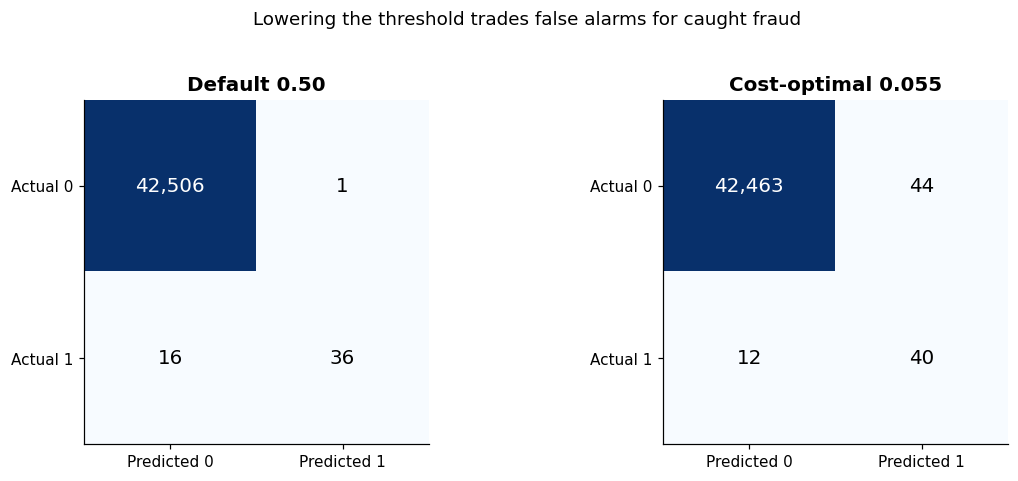

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, (label, threshold) in zip(
    axes,
    [("Default 0.50", 0.50), (f"Cost-optimal {best_threshold:.3f}", best_threshold)],
):
    pred = (proba_test >= threshold).astype(int)
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted 0", "Predicted 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual 0", "Actual 1"])
    ax.set_title(label)
    ax.grid(False)

fig.suptitle("Lowering the threshold trades false alarms for caught fraud", y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

At 0.5 the model makes almost no false-positive errors, but misses 16 of 52 frauds. At the
cost-optimal threshold it misses 12 and accepts 44 false alarms. Neither is "wrong"; they are
different operating points on the same ranking.

### 5.5 What the Random Forest uses

Impurity-based feature importance is not causal and is biased toward features with many split points,
but it is a useful sanity check. The top features should be the PCA components that separate fraud
from legitimate transactions, not `Amount` alone.

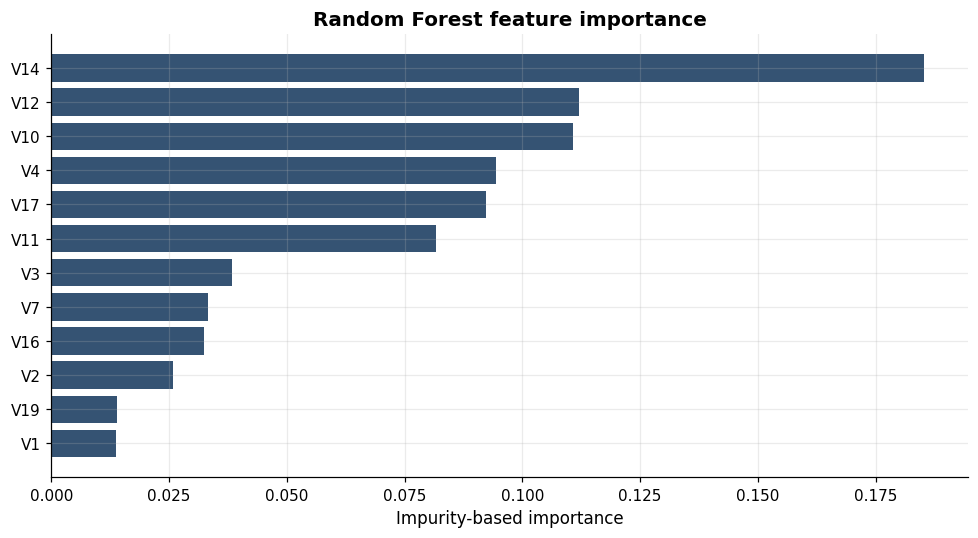

,importance
V14,0.185
V12,0.112
V10,0.111
V4,0.094
V17,0.092
V11,0.082
V3,0.038
V7,0.033
V16,0.032
V2,0.026


In [11]:
rf = fitted["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
top = importance.head(12).sort_values()
ax.barh(top.index, top.values, color=NAVY, alpha=0.85)
ax.set_xlabel("Impurity-based importance")
ax.set_title("Random Forest feature importance")
plt.tight_layout()
plt.show()

importance.head(10).to_frame("importance").round(3)

`V14`, `V12`, `V10`, `V4`, and `V17` lead. These are PCA components, so I cannot say what they mean
in business terms. That is a real limitation of this dataset: the model can rank transactions, but it
cannot explain "why" in a way a fraud analyst can act on. A production system would keep the original
features (merchant category, country, device, velocity) so that alerts are explainable.

None of the engineered features (`log_amount`, `hour_sin`, `hour_cos`) appears in the top 10. They
add some signal, but the anonymised components carry most of it.

### 5.6 Does class weighting help?

I fit a second Random Forest without class weights and compare the two. This isolates the effect of
the weighting, though it is not a full ablation (the threshold also matters).

In [12]:
rf_unweighted = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=42,
).fit(X_train, y_train)

rows = []
for label, model in [("RF (no class weight)", rf_unweighted), ("RF (balanced)", fitted["Random Forest"])]:
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "model": label,
        "PR_AUC": average_precision_score(y_test, proba),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "precision@0.5": precision_score(y_test, (proba >= 0.5).astype(int), zero_division=0),
        "recall@0.5": recall_score(y_test, (proba >= 0.5).astype(int)),
    })

pd.DataFrame(rows).set_index("model").round(3)

,PR_AUC,ROC_AUC,precision@0.5,recall@0.5
model,,,,
RF (no class weight),0.743,0.951,0.972,0.673
RF (balanced),0.782,0.935,0.973,0.692


Class weighting raises PR-AUC from **0.743 to 0.782** and recall at 0.5 from **67.3% to 69.2%**,
while lowering ROC-AUC from **0.951 to 0.935**. That is the same trade-off as before, and it is a good
illustration that "better ROC" is not the same as "better fraud model".

The weighting does not create information; it changes which errors the model prioritises. If the
business cares more about recall, weighting is a cheap way to shift the operating point. If it cares
more about precision, an unweighted model with a high threshold may be preferable. The right choice
depends on the cost ratio and the review capacity.

## 6. Evaluation in plain language

**PR-AUC 0.782 (Random Forest).** Average precision summarises the precision-recall curve. A random
classifier would score about 0.0012 (the base rate); 0.782 is roughly 640× the base rate. That sounds enormous, but the absolute precision at a useful recall is
still only 48–97%, depending on the threshold.

**ROC-AUC 0.935.** High, but the logistic model's 0.977 is higher and its alerts are worse. Do not
use ROC-AUC alone for rare-event problems.

**At threshold 0.5:** 36 of 52 frauds caught (69.2%), 1 false alarm, precision 97.3%. The review team
gets 37 alerts out of 42,559 transactions. This is a conservative operating point: it protects
analyst time and accepts 16 missed frauds.

**At the cost-optimal threshold:** 40 of 52 frauds caught (76.9%), 44 false alarms, precision 47.6%.
Expected cost per transaction is lower under the assumed $150/$5 costs. This is the operating point I
would recommend if the review team can handle ~0.2% of transactions.

**What the model cannot do.** It cannot explain a fraud in business terms, it cannot adapt to a new
fraud pattern without retraining, and it cannot tell you the cost ratio. Those are decisions for the
business, and the model should be one input to them.

## 7. Limitations and next steps

**Two days of data.** The dataset covers about 48 hours. There is no weekly or seasonal pattern, and
the temporal split is short. A production model needs months of history and drift monitoring.

**Anonymised features.** `V1`–`V28` are PCA components. The model can discriminate but cannot explain.
For analyst trust and regulatory review, keep interpretable features (merchant, country, device,
velocity) and use the PCA components only as additional signal.

**Temporal drift.** Fraud patterns change quickly. A model trained on the first 70% of a two-day
window may not generalise to next month. A rolling-origin evaluation and periodic retraining are
essential.

**Label quality.** "Fraud" here means a chargeback was recorded. Some fraud is never reported, and
some chargebacks are friendly fraud. The labels are noisy.

**Duplicates.** I dropped exact duplicates, but near-duplicates may remain. They can inflate
apparent performance if they straddle the split.

**Imbalance handling.** I used class weights. SMOTE, random undersampling, and focal loss are
reasonable alternatives; the best choice depends on the data and the cost ratio. I would compare them
with the same temporal split and the same PR-AUC/threshold analysis.

**Cost assumptions.** The $150/$5 numbers are illustrative. Real costs include chargeback fees,
customer lifetime value, analyst salary, and false-decline friction. The threshold should be
recomputed with the business's actual numbers.

**Calibration.** The predicted probabilities are not calibrated, especially with class weights. A
0.5 score does not mean a 50% chance of fraud. If the business needs risk estimates (e.g. for
pricing), calibrate with Platt scaling or isotonic regression.

**Single model.** A production system would combine the model score with rules (velocity, geography,
merchant risk) and a feedback loop from analyst decisions. The model is one component, not the whole
system.

**Next steps:** (1) rolling-origin backtest; (2) compare SMOTE/undersampling; (3) calibrate
probabilities; (4) permutation importance and SHAP on a sample; (5) cost-sensitive learning with real
costs; (6) drift monitoring on feature distributions; (7) explainable features for analyst review.

## 8. References

- Kaggle, *Credit Card Fraud Detection* (ULB):
  https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Dal Pozzolo, A., Caelen, O., Le Borgne, Y.-A., Waterschoot, S., & Bontempi, G. (2014).
  *Learned lessons in credit card fraud detection from a practitioner perspective.* Expert Systems
  with Applications.
- scikit-learn, *Precision-Recall*:
  https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html
- scikit-learn, *RandomForestClassifier*:
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- scikit-learn, *HistGradientBoostingClassifier*:
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html

---

*Reproduce: `pip install -r ../requirements.txt`, place `creditcard.csv` in `data/`, then run the
notebook top to bottom. Runtime is about 1–2 minutes on a laptop.*